# Why Random Folds Fail for Overlapping Financial Labels

Each financial label uses an information interval, and the indicator records whether two labels share any time:

$$
I_i=[s_i,e_i],
\qquad
O_{ij}=\one\!\left\{I_i\cap I_j\neq\varnothing\right\}.
$$

Here, $I_i$ is the information interval for observation $i$; $s_i$ and $e_i$ are its start and end times. $O_{ij}$ is one when observations $i$ and $j$ overlap and zero otherwise; $\one\{\cdot\}$ is the indicator function.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("16_temporal_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "random"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
input_root = joinpath("..","data","chapter16_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
primitive = TOML.parsefile(manifest_path)["random_fold_permutation"]
permutation_path = joinpath(input_root,primitive["file"])
permutation = CSV.read(permutation_path,DataFrame).position
@assert sort(permutation)==collect(1:count_observations)
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && length(dates)==length(event_times)==length(public_y)
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

function geometry(collections,title_text,stem)
    panels = []
    for (name,splits) in collections
        values = split_matrix(splits)
        panel = heatmap(1:count_observations,1:length(splits),values;color=cgrad(split_colors[1:3],categorical=true),clims=(-.5,2.5),colorbar=false,yflip=true,yticks=1:length(splits),ylabel="Fold",title=name,grid=false,xlims=(.5,count_observations+.5))
        push!(panels,split_legend!(panel))
    end
    plot!(panels[end];xlabel="Observation in time order")
    figure = plot(panels...;layout=(length(panels),1),size=(1300,820),plot_title=title_text,plot_titlefontsize=13,left_margin=8Plots.mm,right_margin=16Plots.mm)
    save_figure(figure,paths,stem)
    return nothing
end

function fitted_model!(records,fold,x,y;weights=ones(length(y)))
    model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,class_weight=nothing,standardize=false,tol=1e-4,max_iter=1000)
    @assert model.converged
    b = model.coefficients
    push!(records,(fold=fold,training_observations=length(y),intercept=model.intercept,b1=b[1],b2=b[2],b3=b[3],b4=b[4],b5=b[5],b6=b[6],objective=model.objective,gradient_norm=model.gradient_norm,iterations=model.iterations,converged=model.converged))
    return model
end

function score_splits(name,splits,key)
    predictions,scores = fill(NaN,count_observations),fill(NaN,count_observations)
    records,models = NamedTuple[],NamedTuple[]
    for (fold,(train,test)) in enumerate(splits)
        accuracy = NaN
        if !isempty(train) && length(unique(public_y[train]))==2
            model = fitted_model!(models,fold,public_x[train,:],public_y[train])
            predictions[test] = BookEstimators.predict(model,public_x[test,:])
            scores[test] = BookEstimators.decision_function(model,public_x[test,:])
            accuracy = mean(predictions[test].==public_y[test])
        end
        push!(records,(method=name,fold=fold,training=length(train),test=length(test),accuracy=accuracy))
    end
    result = DataFrame(records)
    rename!(result,["Method","Fold","Training observations","Test observations","Accuracy"])
    save_splits(key,splits)
    save_data(DataFrame(models),paths,key*"_fits")
    save_data(DataFrame(position=collect(1:count_observations),date=dates,actual=public_y,prediction=predictions,score=scores),paths,key*"_predictions")
    save_data(result,paths,key*"_fold_scores")
    return result,predictions
end

function score_summary(frame;with_count=false)
    records = NamedTuple[]
    for name in unique(frame.Method)
        values = filter(isfinite,frame[frame.Method.==name,"Accuracy"])
        push!(records,(method=name,count=length(values),mean=mean(values),spread=std(values),minimum=minimum(values),maximum=maximum(values)))
    end
    result = DataFrame(records)
    rename!(result,["Method","Scored folds","Mean accuracy","Accuracy spread","Minimum accuracy","Maximum accuracy"])
    return with_count ? result : select(result,Not("Scored folds"))
end


score_summary (generic function with 1 method)

## Public Data

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Market","Bar length","Label horizon","Analysis start","Analysis end","Observations"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Bitcoin to Tether spot market","15 minutes","2 hours",format_time(first(dates)),format_time(last(dates)),"2,951"])
table(data_provenance,"data_provenance","Fixed public observations used in Chapter 14.")


Row,Field,Value
,String,String
1,Archive,BTCUSDT-1m-2021-01.zip
2,Provider,Binance Data Vision
3,Market,Bitcoin to Tether spot market
4,Bar length,15 minutes
5,Label horizon,2 hours
6,Analysis start,2021-01-01 04:15:00
7,Analysis end,2021-01-31 21:45:00
8,Observations,"2,951"


Cross-validation averages the held-out loss across folds, using a fit that excludes the current test fold:

$$
\widehat R_{\mathrm{CV}}
=\frac{1}{K}\sum_{k=1}^{K}
\frac{1}{|S_k|}\sum_{i\in S_k}
\ell\!\left(y_i,\widehat f^{(-k)}(x_i)\right).
$$

Here, $K$ is the number of folds; $S_k$ is test fold $k$; $|S_k|$ is its size; $x_i$ and $y_i$ are features and label. $\widehat f^{(-k)}$ is fitted without $S_k$; $\ell$ is the chosen loss; $\widehat R_{\mathrm{CV}}$ is average held-out loss.

## Fold Geometry

Row,Method,Training observations,Test observations,Overlapping training labels,Overlap share,Training rows not earlier than first test row
,String,Float64,Float64,Float64,Float64,Float64
1,Random folds,2459.17,491.833,2327.5,0.946459,2455.17
2,Ordered folds,2459.17,491.833,13.3333,0.00542204,1229.17
3,Purged folds,2445.83,491.833,0.0,0.0,1222.5


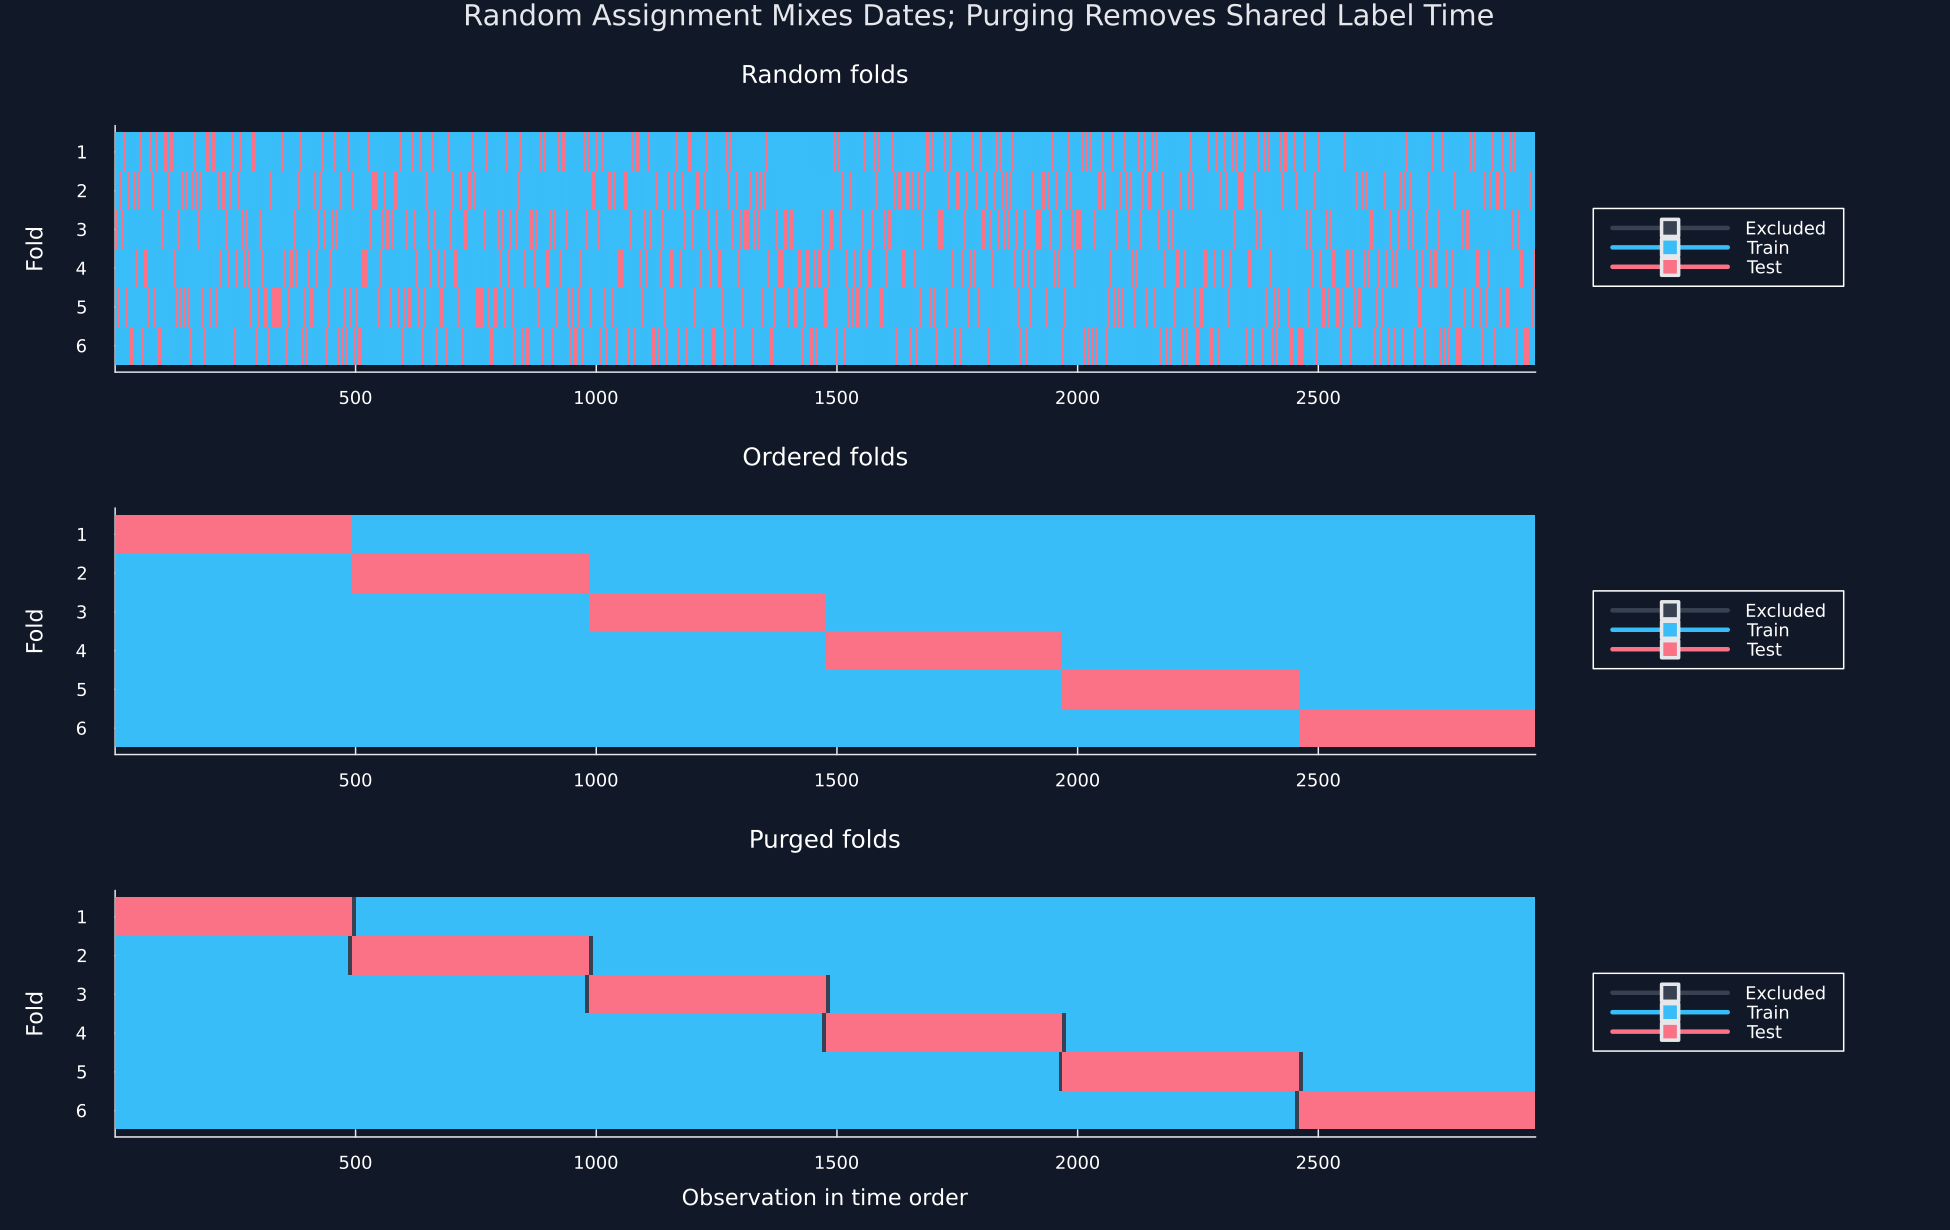

In [3]:
n_splits = 6
random_splits = cv_split(KFoldCV(n_splits;shuffle=true,random_seed=14),count_observations;permutation)
ordered_splits = cv_split(KFoldCV(n_splits),count_observations)
purged_splits = cv_split(PurgedKFoldCV(n_splits,dates,event_times;embargo=0.))
collections = [("Random folds",random_splits),("Ordered folds",ordered_splits),("Purged folds",purged_splits)]
overlap_records = NamedTuple[]
for (method,splits) in collections, (fold,(train,test)) in enumerate(splits)
    overlap = overlap_count(train,test)
    push!(overlap_records,(method=method,fold=fold,training=length(train),test=length(test),overlap=overlap,share=overlap/length(train),not_earlier=count(>=(minimum(test)),train)))
end
overlap_audit = DataFrame(overlap_records)
rename!(overlap_audit,["Method","Fold","Training observations","Test observations","Overlapping training labels","Overlap share","Training rows not earlier than first test row"])
overlap_summary = combine(groupby(overlap_audit,:Method;sort=false),[name=>mean=>name for name in names(overlap_audit)[3:end]])
table(overlap_summary,"fold_overlap_summary","Information overlap and time order across six public-data folds.")
save_data(overlap_audit,paths,"fold_overlap_audit")
geometry(collections,"Random Assignment Mixes Dates; Purging Removes Shared Label Time","random_ordered_purged_geometry")


The leakage count measures how many training labels share information time with at least one test label in fold $k.$:

$$
L_k=\sum_{i\in T_k}
\one\!\left\{\exists j\in S_k:O_{ij}=1\right\},
\qquad
\lambda_k=\frac{L_k}{|T_k|}.
$$

Here, $T_k$ and $S_k$ are the training and test sets; $O_{ij}$ is the overlap indicator; $L_k$ is the count. $|T_k|$ is the training size; $\lambda_k$ is the overlapping share of the training set; $k$ indexes folds.

## Public Classification Results

Row,Method,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy,Overlap share
,String,Float64,Float64,Float64,Float64,Float64?
1,Random folds,0.517107,0.0152423,0.501018,0.536585,0.946459
2,Ordered folds,0.491364,0.0324178,0.441057,0.52439,0.00542204
3,Purged folds,0.493058,0.0275451,0.457317,0.522358,0.0


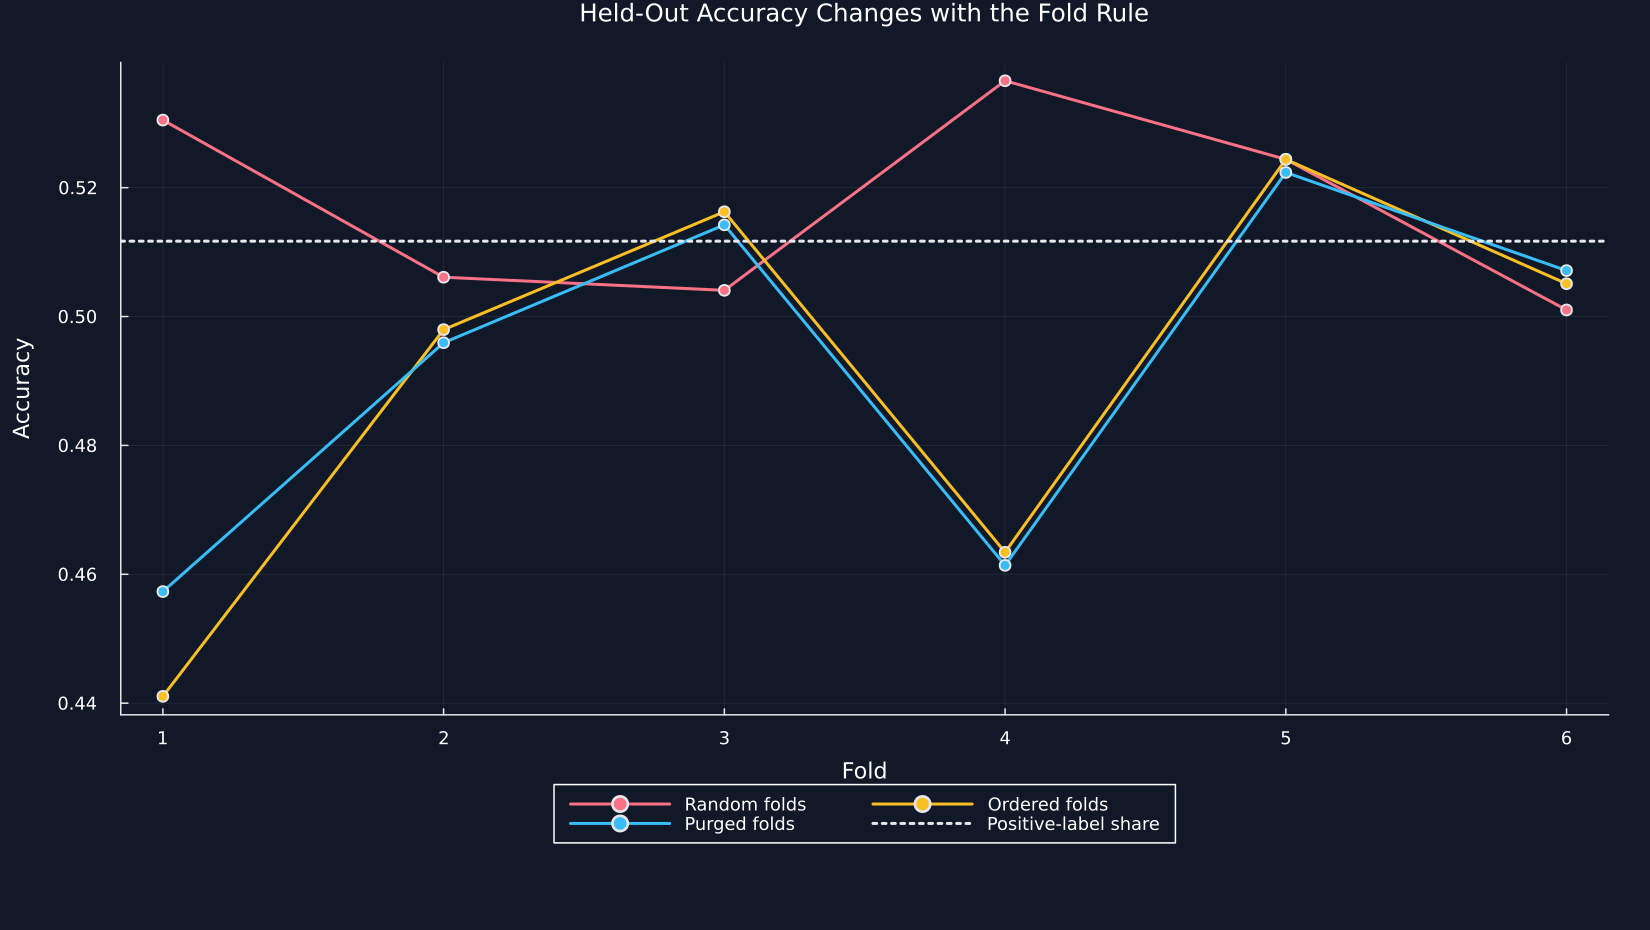

In [4]:
score_frames,prediction_sets = DataFrame[],Dict{String,Vector{Float64}}()
for ((method,splits),key) in zip(collections,["random","ordered","purged_zero"])
    scores,predictions = score_splits(method,splits,key)
    push!(score_frames,scores)
    prediction_sets[method] = predictions
end
fold_scores = vcat(score_frames...)
summary = score_summary(fold_scores)
summary = leftjoin(summary,select(overlap_summary,["Method","Overlap share"]);on="Method",order=:left)
table(summary,"public_validation_summary","Public classification accuracy and label overlap by validation rule.")
save_data(fold_scores,paths,"public_fold_accuracy")
figure = plot(;title="Held-Out Accuracy Changes with the Fold Rule",xlabel="Fold",ylabel="Accuracy",xticks=1:6,size=(1100,620),legend=:outerbottom,legendcolumns=2)
for (method,color) in zip(first.(collections),[palette.rose,palette.amber,palette.cyan])
    selected = fold_scores[fold_scores.Method.==method,:]
    plot!(figure,selected.Fold,selected.Accuracy;marker=:circle,color,label=method)
end
hline!(figure,[mean(public_y)];color=palette.text,linestyle=:dot,label="Positive-label share")
save_figure(figure,paths,"public_fold_accuracy")


## Tests

In [5]:
@assert count_observations>2900
@assert length(dates)==length(public_y)==length(event_times)
@assert length(random_splits)==n_splits
@assert length(ordered_splits)==n_splits
@assert length(purged_splits)==n_splits
@assert size(overlap_audit)==(18,7)
@assert only(overlap_summary[overlap_summary.Method.=="Random folds","Overlap share"])>.90
@assert only(overlap_summary[overlap_summary.Method.=="Ordered folds","Overlap share"])>0
@assert only(overlap_summary[overlap_summary.Method.=="Purged folds","Overlap share"])==0
@assert size(fold_scores)==(18,5)
@assert all(value->0<=value<=1,fold_scores.Accuracy)
@assert reduce(vcat,last.(ordered_splits))==collect(1:count_observations)
@assert isfile(joinpath(paths.figures,"random_ordered_purged_geometry.pdf"))
@assert isfile(joinpath(paths.figures,"public_fold_accuracy.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"fold_overlap_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_validation_summary.tex"))
